In [1]:
import os
import matplotlib.pyplot as plt
from osfile.manager import findFile
from slide.tile import SlidePatcher, TileEncoder
from slide.utils import get_slide_reader, print_attrs, read_h5_coords, read_h5_features
from slide.draw import draw_cut
import h5py
from slide.tile_encoder.load import encoder_factory
import numpy as np
from draw.palette import mosaic
import torch


In [2]:
wsi_path = "/cluster/CBIO/data1/mblons/orion/data/SURGEN/WSI/SR386_WSIs_ome/SR386_40X_HE_T001_01.ome.tiff"
print(wsi_path)
reader = get_slide_reader(wsi_path)
try:
    SLIDE = reader(wsi_path)
except Exception as e:
    print(f"Error while trying to open wsi: {e}")
print(f"mpp at level 0: {SLIDE.mpp}")
print(f"magnification: {SLIDE.magnification}")
print(f"level count: {SLIDE.level_count}")
print(f"level dimensions: {SLIDE.level_dimensions}")
print(f"level downsamples {SLIDE.level_downsamples}")


/cluster/CBIO/data1/mblons/orion/data/SURGEN/WSI/SR386_WSIs_ome/SR386_40X_HE_T001_01.ome.tiff
mpp at level 0: 0.5
magnification: 20
level count: 8
level dimensions: [(63758, 40190), (31879, 20095), (15939, 10047), (7969, 5023), (3984, 2511), (1992, 1255), (996, 627), (498, 313)]
level downsamples [1.0, 2.0, 4.000199064397332, 8.001194505275732, 16.00557546794106, 32.02390438247012, 64.09888357256779, 128.40255591054313]


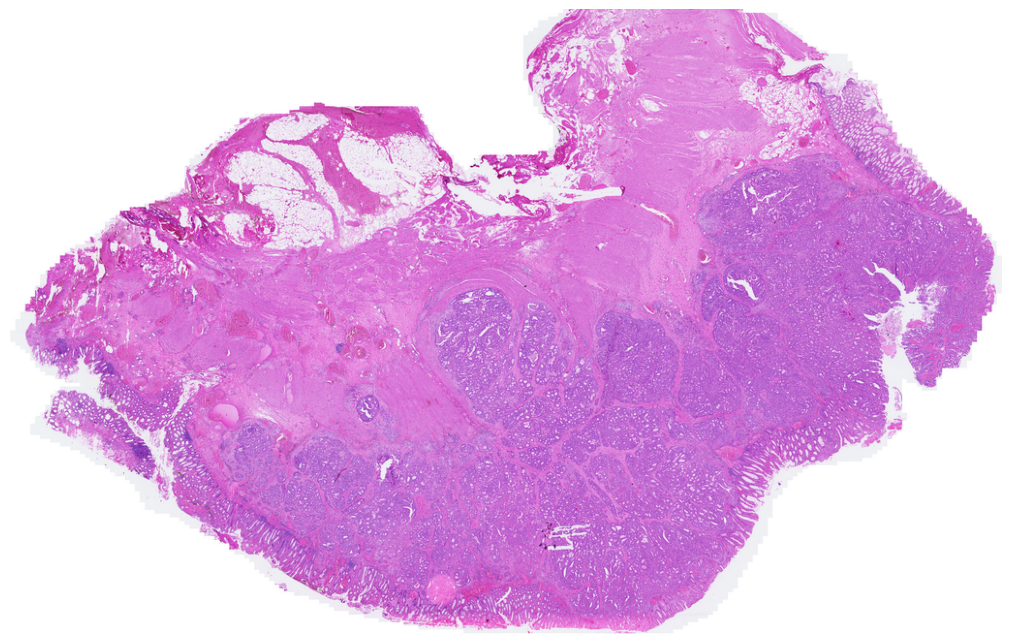

In [3]:
thumbnail = SLIDE.get_thumbnail(size=(1024, 1024))
fig, ax = plt.subplots(1, 1, figsize=(10, 10), layout="constrained")
ax.set_axis_off()
ax.imshow(thumbnail, aspect="equal")
plt.show()

In [4]:
PATCH_SIZE = 224
SOURCE_MAG = SLIDE.magnification
TARGET_MAG = 20
OVERLAP = 0
MASK_DOWNSAMPLE = 64
MASK_TOLERANCE = 0.5
OUTPUT_DIR = f"./1_tutorial/tile_feat_{TARGET_MAG}x_{PATCH_SIZE}px_{OVERLAP}px_overlap"

patcher = SlidePatcher(
    SLIDE,
    mag_0=SOURCE_MAG,
    mag_target=TARGET_MAG,
    patch_size=PATCH_SIZE,
    overlap=OVERLAP,
    mask_downsample=MASK_DOWNSAMPLE,
    mask_tolerance=MASK_TOLERANCE,
    mask_strategy="luminosity",
    xywh_only=False,
    dst=OUTPUT_DIR,
)
print(f"target mag: {patcher.mag_target}")
print(f"level: {patcher.level}")
print(f"mask downsampling: {patcher.mask_downsample}")
print(f"mask level: {patcher.level_mask}")

target mag: 20
level: 0
mask downsampling: 64
mask level: 5


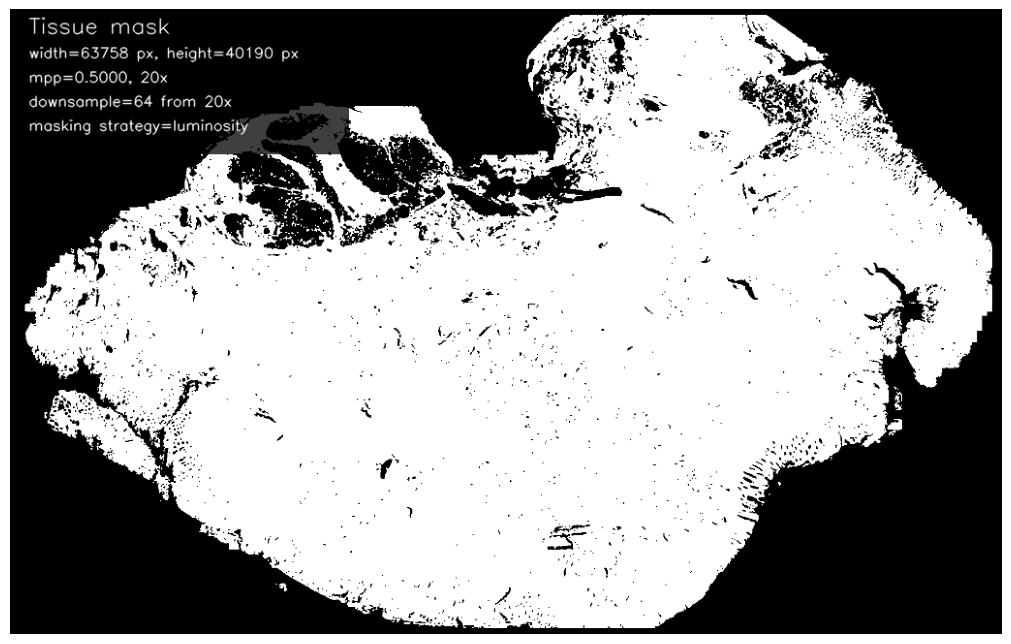

./1_tutorial/tile_feat_20x_224px_0px_overlap/segmentation/SR386_40X_HE_T001_01.ome.jpg


In [6]:
# visu mask
seg_dir = os.path.join(OUTPUT_DIR, "segmentation")
seg_path = patcher.visualize_tissue_seg(size=(1024, 1024), save_seg=seg_dir, show=True)
print(seg_path)

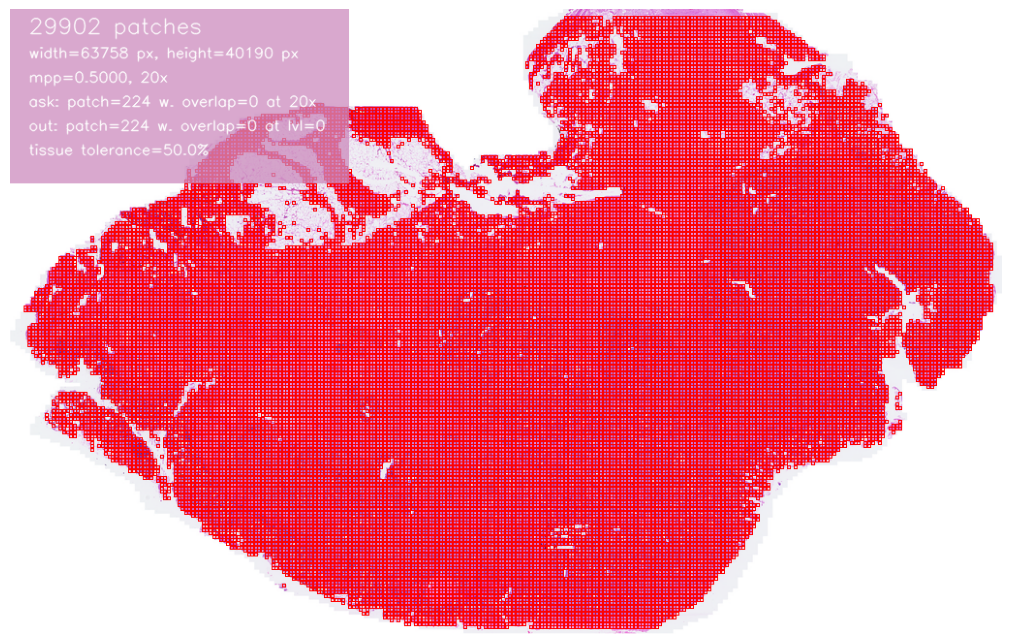

./1_tutorial/tile_feat_20x_224px_0px_overlap/visualization/SR386_40X_HE_T001_01.ome.jpg


In [7]:
# visu cut
visu_dir = os.path.join(OUTPUT_DIR, "visualization")
cut_path = patcher.visualize_cut(size=(1024, 1024), save_cut=visu_dir, show=True)
print(cut_path)

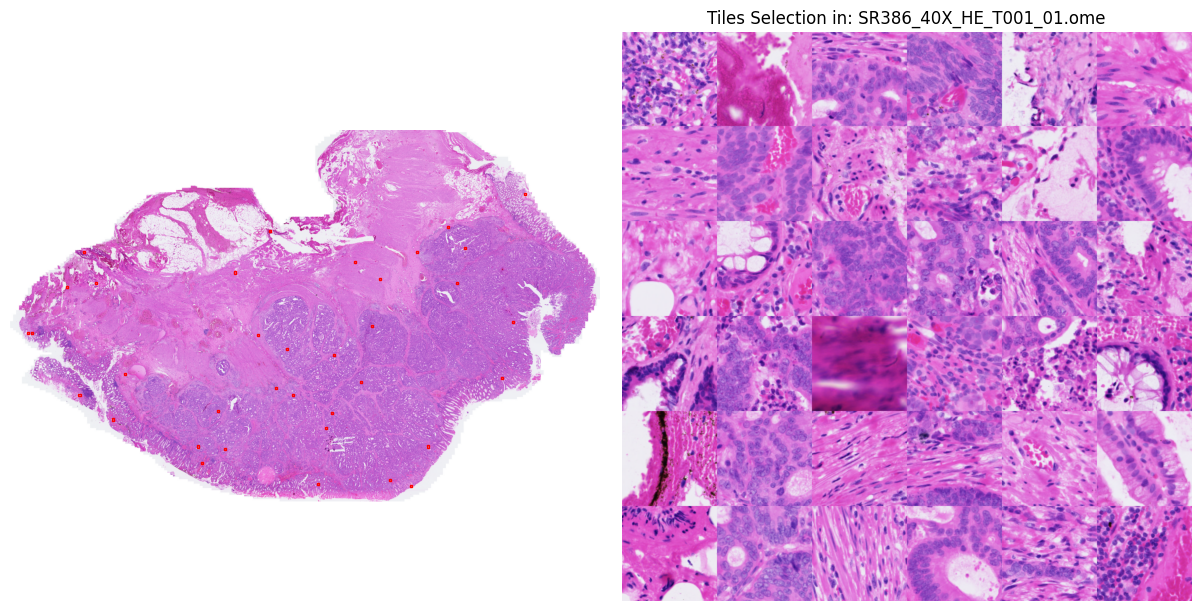

In [8]:
# get collection of tiles
# Can use slide.tile EncodingSampler
nt = 36
idx_samples = np.random.choice(patcher.nb_valid_patches, nt, replace=False)
iimg = [patcher.get_tile(*patcher.valid_patches[i]) for i in idx_samples]
samples_pos = np.array(patcher.valid_patches)[idx_samples]
fig, ax = plt.subplots(1, 2, figsize=(12, 6), layout="constrained")
draw_cut(
    wsi_path,
    xywh=samples_pos,
    analyse_level=patcher.level,
    level_to_view=4,
    ax=ax[0],
    show=False,
)
ax[1].set_title(f"Tiles Selection in: {SLIDE.name}")
mosaic(iimg, size=(PATCH_SIZE, PATCH_SIZE), ax=ax[1])

In [25]:
ENCODER = "hoptimus1"
DEVICE = "cpu"
BATCH_SIZE = 512
model = encoder_factory(ENCODER)
model.to(DEVICE)
encoder = TileEncoder(
    SLIDE,
    tile_encoder=model,
    coords_path=os.path.join(OUTPUT_DIR, "patches", f"{SLIDE.name}_patches.h5"),
    device=DEVICE,
    batch_max=BATCH_SIZE,
    feat_only=False,
    dst=OUTPUT_DIR,
    verbose=True,
)

4_A_AAAA1168.ome enc with hoptimus1:   0%|          | 0/1 [00:00<?, ?batch/s][W801 12:29:43.701367561 NNPACK.cpp:61] Could not initialize NNPACK! Reason: Unsupported hardware.


: 

: 

In [ ]:
# visu feat
umap_dir = os.path.join(OUTPUT_DIR, f"cluster_{ENCODER}")
umap_path = encoder.visualize_embeddings(
    pcs=0, neighbors=20, resolution=0.2, save_cluster=umap_dir, show=True
)
print(umap_path)